Dataset from Kaggle is now loaded onto colab Files and will be unzipped.

#Import Python Libraries

In [49]:

import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OrdinalEncoder
from sklearn.preprocessing  import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.metrics import confusion_matrix, accuracy_score, recall_score, precision_score,classification_report, f1_score, roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.model_selection import cross_val_score
from sklearn.neural_network import MLPClassifier
from sklearn.inspection import permutation_importance



#Data Load
Data is loaded in Python.

In [3]:
url = "https://raw.githubusercontent.com/Sponono/RPDA8412/baed8f70f9ecbd5e6bc29d9d9a4b78b073998dd6/credit_risk_dataset.csv"
df = pd.read_csv(url)

df.head()

,Column1,age,gender,employment_status,annual_income,account_age_months,avg_monthly_balance,num_deposits_per_month,avg_deposit_amount,debit_card_usage_frequency,...,atm_withdrawal_frequency,credit_score,num_open_loans,total_outstanding_debt,late_payment_count,loan_default_history,fraud_flag,loan_application_amount,credit_risk,risk_category
0,CUST_00000,58,Male,Unemployed,58137.75119,115,524.679407,1,171.342369,49,...,1,539,5,14435.42344,2,0,0,15510.576880,1,High Risk
1,CUST_00001,48,Male,Self-Employed,26174.92283,32,2635.203357,1,985.607164,1,...,2,494,5,11263.09934,2,0,0,14819.436500,1,High Risk
2,CUST_00002,34,Other,Unemployed,75566.83726,14,2334.341061,9,994.310119,42,...,6,437,3,15017.14413,5,0,0,10909.806510,1,High Risk
3,CUST_00003,62,Male,Self-Employed,35197.96152,179,2425.384332,10,366.115346,4,...,7,809,1,12626.13848,2,0,0,500.000000,0,Low Risk
4,CUST_00004,27,Female,Self-Employed,12136.99835,225,10.000000,8,786.752258,16,...,3,522,1,13576.70432,4,0,0,9514.591618,1,High Risk


####Data Structure
This step focuses on understanding and validating the dataset structure. The data structure is confirmed by pulling the first 5 records of the dataset. (GeeksforGeeks, 2026)

In [4]:
df.head()

,Column1,age,gender,employment_status,annual_income,account_age_months,avg_monthly_balance,num_deposits_per_month,avg_deposit_amount,debit_card_usage_frequency,...,atm_withdrawal_frequency,credit_score,num_open_loans,total_outstanding_debt,late_payment_count,loan_default_history,fraud_flag,loan_application_amount,credit_risk,risk_category
0,CUST_00000,58,Male,Unemployed,58137.75119,115,524.679407,1,171.342369,49,...,1,539,5,14435.42344,2,0,0,15510.576880,1,High Risk
1,CUST_00001,48,Male,Self-Employed,26174.92283,32,2635.203357,1,985.607164,1,...,2,494,5,11263.09934,2,0,0,14819.436500,1,High Risk
2,CUST_00002,34,Other,Unemployed,75566.83726,14,2334.341061,9,994.310119,42,...,6,437,3,15017.14413,5,0,0,10909.806510,1,High Risk
3,CUST_00003,62,Male,Self-Employed,35197.96152,179,2425.384332,10,366.115346,4,...,7,809,1,12626.13848,2,0,0,500.000000,0,Low Risk
4,CUST_00004,27,Female,Self-Employed,12136.99835,225,10.000000,8,786.752258,16,...,3,522,1,13576.70432,4,0,0,9514.591618,1,High Risk


####Size of Data
This step helps understand the number of rows (observations) and columns (features) in the dataset. This gives an overview of the dataset's size and structure. (GeeksforGeeks, 2026)

In [5]:
df.shape

(5000, 23)

There are 5000 rows (observations) and 23 columns

####Data Overview
This step provides an overview of the dataset by displaying the number of records in each column, type of data, whether any values are missing and how much memory the dataset uses.(GeeksforGeeks, 2026)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 23 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Column1                     5000 non-null   object 
 1   age                         5000 non-null   int64  
 2   gender                      5000 non-null   object 
 3   employment_status           5000 non-null   object 
 4   annual_income               5000 non-null   float64
 5   account_age_months          5000 non-null   int64  
 6   avg_monthly_balance         5000 non-null   float64
 7   num_deposits_per_month      5000 non-null   int64  
 8   avg_deposit_amount          5000 non-null   float64
 9   debit_card_usage_frequency  5000 non-null   int64  
 10  debit_card_spending         5000 non-null   float64
 11  mobile_banking_logins       5000 non-null   int64  
 12  online_transfer_frequency   5000 non-null   int64  
 13  atm_withdrawal_frequency    5000 

#Data Cleaning
Null values and duplicates are checked to ensure data completeness and prevent biased or misleading results, and data types are verified to confirm that each variable is correctly classified for accurate analysis.

In [7]:
df.isnull().sum()

,0
Column1,0
age,0
gender,0
employment_status,0
annual_income,0
account_age_months,0
avg_monthly_balance,0
num_deposits_per_month,0
avg_deposit_amount,0
debit_card_usage_frequency,0


The above results confirm that there are no Null values in the dataset.

In [8]:
df.duplicated().sum()

np.int64(0)

The above results confirm that there are no duplicated records in the dataset.

In [9]:
df.isna().mean().sort_values(ascending=False).head(20)


,0
Column1,0.0
age,0.0
gender,0.0
employment_status,0.0
annual_income,0.0
account_age_months,0.0
avg_monthly_balance,0.0
num_deposits_per_month,0.0
avg_deposit_amount,0.0
debit_card_usage_frequency,0.0


The above results confirm that there are no missing values in the dataset.

#####Removing unnecessary columns
Deleting Column1 and risk_category because they are not numerical columns, Column1 is an unique identifier in the dataset, and the risk_category is the categorical column for credit_risk. These 2 columns will not be used in the analysis.

In [10]:
df = df.drop(columns=['Column1', 'risk_category'])

####Data Encoding
Categorical variables such as ‘gender’ and ‘employment_status’ are converted into numeric formats using one-hot encoder

In [11]:
# Female=0 and Male=1
gender_categories = ['Female', 'Male', 'Other']
# Employed=0, Self-Employed=1, Unemployed=2
employment_categories = ['Employed', 'Self-Employed', 'Unemployed']

df['gender'] = df['gender'].astype(str)
df['employment_status'] = df['employment_status'].astype(str)

encoder = OrdinalEncoder(
    categories=[gender_categories, employment_categories],
    dtype=int )

df[['gender', 'employment_status']] = encoder.fit_transform(df[['gender', 'employment_status']])

df['employment_status'] = df['employment_status'] + 1

In [12]:
df.head()

,age,gender,employment_status,annual_income,account_age_months,avg_monthly_balance,num_deposits_per_month,avg_deposit_amount,debit_card_usage_frequency,debit_card_spending,...,online_transfer_frequency,atm_withdrawal_frequency,credit_score,num_open_loans,total_outstanding_debt,late_payment_count,loan_default_history,fraud_flag,loan_application_amount,credit_risk
0,58,1,3,58137.75119,115,524.679407,1,171.342369,49,768.877511,...,16,1,539,5,14435.42344,2,0,0,15510.576880,1
1,48,1,2,26174.92283,32,2635.203357,1,985.607164,1,580.287786,...,1,2,494,5,11263.09934,2,0,0,14819.436500,1
2,34,2,3,75566.83726,14,2334.341061,9,994.310119,42,564.013508,...,5,6,437,3,15017.14413,5,0,0,10909.806510,1
3,62,1,2,35197.96152,179,2425.384332,10,366.115346,4,838.489200,...,7,7,809,1,12626.13848,2,0,0,500.000000,0
4,27,0,2,12136.99835,225,10.000000,8,786.752258,16,462.495522,...,16,3,522,1,13576.70432,4,0,0,9514.591618,1


###Train Model
The dataset is split into training and testing sets, using an 80/20 split, to enable proper model training and validation on unseen data.

In [26]:
x = df.drop(columns=['credit_risk'])
y = df['credit_risk']

x_train, x_test, y_train, y_test = train_test_split(
    x, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


###Checking class balance

In [27]:
print(df['credit_risk'].value_counts())
print(df['credit_risk'].value_counts(normalize=True))

credit_risk
1    3829
0    1171
Name: count, dtype: int64
credit_risk
1    0.7658
0    0.2342
Name: proportion, dtype: float64


The target variable "credit_risk" is a bit imbalanced, with more High-Risk customers than Low-Risk customers in the dataset. There are 3,829 High-Risk records and 1,171 Low-Risk records, this means that the model has more examples of High-Risk customers to learn from. While this imbalance is not severe, it may cause some algorithms to predict the High-Risk class more often than the Low-Risk class. The model performance will be evaluated using metrics such as precision, recall, F1-score, ROC-AUC, and the confusion matrix, rather than relying on accuracy alone, to ensure that both risk categories are being classified correctly.

###Random Forest

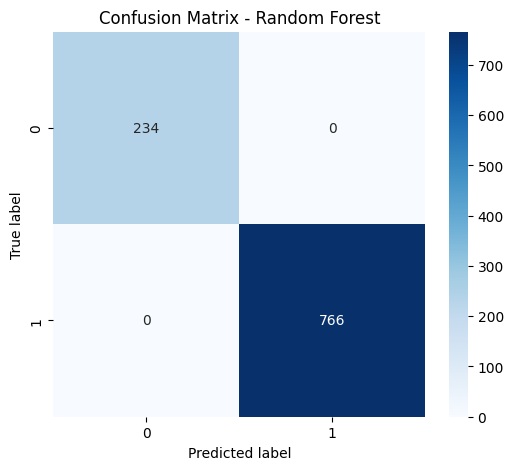

In [28]:
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(x_train, y_train)

y_pred = rf_model.predict(x_test)
y_prob = rf_model.predict_proba(x_test)[:, 1]

cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True
)
plt.title('Confusion Matrix - Random Forest')
plt.xlabel('Predicted label')
plt.ylabel('True label')
plt.show()

The confusion matrix in figure 3 shows that the Random Forest model correctly predicted all the records in the test dataset. Out of the 1,000 records tested, the model correctly classified 234 cases as Class 0 and 766 cases as Class 1. There were no incorrect predictions, meaning that the model did not wrongly classify any borrowers. As a result, the model achieved 100% for accuracy, precision, recall, and F1-score. This shows that the Random Forest model performed very well in identifying the two credit risk categories, with all test records classified correctly.

In [29]:
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("="*50)
print("RANDOM FOREST MODEL EVALUATION")
print("="*50)

print(f"\nAccuracy Score: {accuracy:.3f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print(f"\nROC-AUC Score: {auc:.3f}")

RANDOM FOREST MODEL EVALUATION

Accuracy Score: 1.000

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       234
           1       1.00      1.00      1.00       766

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000


ROC-AUC Score: 1.000


The Random Forest model achieved an accuracy of 99.2%, meaning that it correctly classified almost all observations in the test dataset. It also performed very well in terms of precision, recall, and F1-score, with weighted averages of 0.99. The recall for Class 1 was 1.00, meaning that the model correctly identified all high-risk applicants. The recall for Class 0 was 0.97, showing that only a few low-risk applicants were incorrectly classified. The model also achieved an ROC-AUC score of 1.000, indicating that it could differentiate very well between the two classes. These results show that the Random Forest model performed very well in predicting credit risk. However, because the results are unusually high, further investigation will be done to determine whether data leakage or overfitting may have affected the model's performance.

In [34]:
from sklearn.model_selection import cross_val_score

rf = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

scores = cross_val_score(
    rf,
    x,
    y,
    cv=5,
    scoring='accuracy'
)

print(scores)
print("Mean Accuracy:", scores.mean())

[1. 1. 1. 1. 1.]
Mean Accuracy: 1.0


The five-fold cross-validation model achieved an accuracy score of 1.00 in all five folds, with a mean accuracy of 1.00. This shows that the model performed consistently across different data splits, indicating that it is stable, reliable, and able to accurately predict credit risk.

In [31]:
rf.fit(x, y)

feature_importance = pd.DataFrame({
    'Feature': x.columns,
    'Importance': rf.feature_importances_
})

feature_importance.sort_values(
    by='Importance',
    ascending=False,
    inplace=True
)

print(feature_importance.head(10))

                    Feature  Importance
13             credit_score    0.416669
16       late_payment_count    0.398729
17     loan_default_history    0.059108
18               fraud_flag    0.017894
3             annual_income    0.009728
19  loan_application_amount    0.009653
7        avg_deposit_amount    0.009550
5       avg_monthly_balance    0.009453
15   total_outstanding_debt    0.008797
4        account_age_months    0.008727


Feature importance analysis revealed that credit_score and late_payment_count were the most influential predictors, contributing approximately 41.7% and 39.9% respectively to the model's decision-making process. These findings suggest that a customer's credit score and payment history are the primary factors used by the model to determine credit risk.

###Gradient Boosting (XGBoost)

In [ ]:
xgb = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

xgb.fit(x_train, y_train)
y_pred = xgb.predict(x_test)
y_prob = xgb.predict_proba(x_test)[:,1]

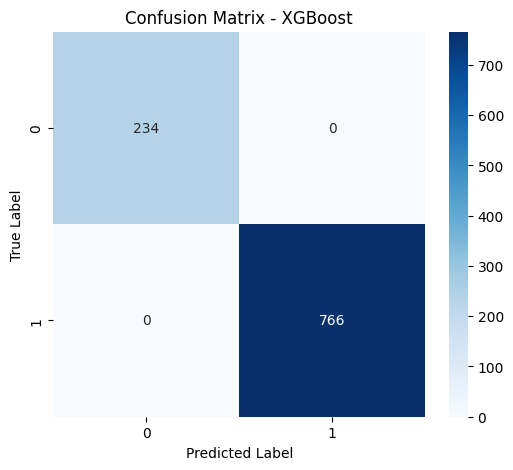

In [ ]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True
)

plt.title('Confusion Matrix - XGBoost')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

In [32]:
accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("="*50)
print("XGBOOST MODEL EVALUATION")
print("="*50)

print(f"\nAccuracy Score: {accuracy:.3f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC-AUC Score: {auc:.3f}")

XGBOOST MODEL EVALUATION

Accuracy Score: 1.000

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       234
           1       1.00      1.00      1.00       766

    accuracy                           1.00      1000
   macro avg       1.00      1.00      1.00      1000
weighted avg       1.00      1.00      1.00      1000


Confusion Matrix
[[234   0]
 [  0 766]]

ROC-AUC Score: 1.000


In [35]:
from sklearn.model_selection import cross_val_score
from xgboost import XGBClassifier

xgb_estimator = XGBClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=6,
    random_state=42,
    eval_metric='logloss'
)

scores = cross_val_score(
    xgb_estimator,
    x,
    y,
    cv=5,
    scoring='accuracy'
)

print(scores)
print("Mean Accuracy:", scores.mean())

[1. 1. 1. 1. 1.]
Mean Accuracy: 1.0


                     Feature  Importance
7         late_payment_count    0.427433
5               credit_score    0.308558
8       loan_default_history    0.189203
9                 fraud_flag    0.065378
6             num_open_loans    0.003228
3  online_transfer_frequency    0.002072
4   atm_withdrawal_frequency    0.001671
2     num_deposits_per_month    0.001072
0                     gender    0.000925
1          employment_status    0.000459


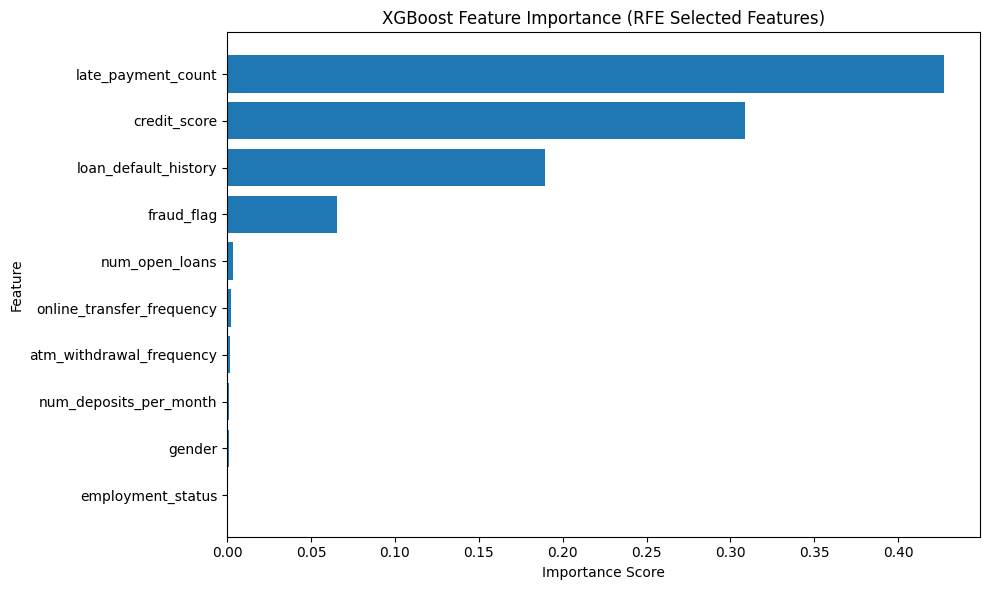

In [41]:
import pandas as pd
import matplotlib.pyplot as plt

# Extract feature importances mapping to the correct selected features used in training
feature_importance = pd.DataFrame({
    'Feature': x_train_sel.columns,
    'Importance': xgb_model.feature_importances_
})

# Sort from highest to lowest importance
feature_importance = feature_importance.sort_values(
    by='Importance',
    ascending=False
)

# Display top features
print(feature_importance)

# Plot top features
plt.figure(figsize=(10, 6))
plt.barh(
    feature_importance['Feature'][:20][::-1],
    feature_importance['Importance'][:20][::-1]
)
plt.xlabel('Importance Score')
plt.ylabel('Feature')
plt.title('XGBoost Feature Importance (RFE Selected Features)')
plt.tight_layout()
plt.show()

The XGBoost model achieved perfect classification performance, with an accuracy, precision, recall, F1-score, and ROC-AUC score of 1.00. The confusion matrix showed that all observations were classified correctly, with no misclassifications recorded. Five-fold cross-validation also produced a mean accuracy of 1.00, confirming that the model performed consistently across different subsets of the data. Feature importance analysis identified late_payment_count, credit_score, and loan_default_history as the most influential variables in predicting customer credit risk.

###Logistic Regression

In [42]:
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_train)
x_test_scaled = scaler.transform(x_test)

In [43]:
lr = LogisticRegression(
    random_state=42,
    max_iter=1000
)
lr.fit(x_train_scaled, y_train)
y_pred = lr.predict(x_test_scaled)
y_prob = lr.predict_proba(x_test_scaled)[:, 1]

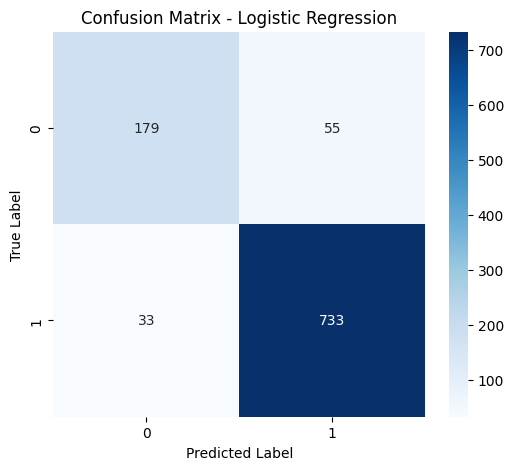

In [44]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True
)

plt.title('Confusion Matrix - Logistic Regression')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

The confusion matrix in Figure 5 above shows that the Logistic Regression model performs well in identifying customers who are likely to default. The model correctly identified 733 defaulting customers, while 33 defaulting customers were incorrectly classified as low-risk. These false negatives are important because failing to identify a high-risk customer could result in financial losses.
The model also correctly identified 179 customers who did not default. However, 55 non-defaulting customers were incorrectly classified as high-risk. These false positives could result in missed lending opportunities.
Overall, the results show that the model is effective at identifying high-risk customers, with a reasonable balance between false positives and false negatives.

In [45]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    roc_auc_score
)

accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("=" * 50)
print("LOGISTIC REGRESSION MODEL EVALUATION")
print("=" * 50)

print(f"\nAccuracy Score: {accuracy:.3f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC-AUC Score: {auc:.3f}")

LOGISTIC REGRESSION MODEL EVALUATION

Accuracy Score: 0.912

Classification Report
              precision    recall  f1-score   support

           0       0.84      0.76      0.80       234
           1       0.93      0.96      0.94       766

    accuracy                           0.91      1000
   macro avg       0.89      0.86      0.87      1000
weighted avg       0.91      0.91      0.91      1000


Confusion Matrix
[[179  55]
 [ 33 733]]

ROC-AUC Score: 0.967


The accuracy score in Figure 5.1 is 91.2%; this means that the model is reliable and performs very well for a loan default prediction. The precision for low risk is correct 84% of the time, and high-risk is correct 93% of the time. The model correctly identifies 76% of low-risk customers, and 96% of high-risk customers. The model works well in recognizing low-risk customers and is also highly effective in identifying high-risk customers, however the recall for low-risk cases is lower at 0.90, implying that there are low-risk customers who are mistakenly misclassified as high-risk. From a business perspective, this approach is effective at reducing bad-debt risk because it identifies almost all high-risk accounts. However, it also has a small downside because it incorrectly restricts almost a quarter of good customers

In [46]:
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_val_score

pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=1000, random_state=42))
])

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=5,
    scoring='accuracy'
)

print(scores)
print("Mean Accuracy:", scores.mean())

[0.909 0.921 0.92  0.933 0.93 ]
Mean Accuracy: 0.9225999999999999


To validate the Logistic Regression model, five-fold cross-validation was performed. The model achieved accuracy scores ranging from 0.909 to 0.933, with a mean accuracy of 0.923. The consistency of these results indicates that the model is stable and performs reliably across different subsets of the data.

In [47]:
coef_df = pd.DataFrame({
    'Feature': x.columns,
    'Coefficient': lr.coef_[0]
})

coef_df['Abs_Coefficient'] = coef_df['Coefficient'].abs()

coef_df = coef_df.sort_values(
    by='Abs_Coefficient',
    ascending=False
)

print(coef_df[['Feature','Coefficient']].head(10))

                       Feature  Coefficient
16          late_payment_count     3.699074
13                credit_score    -3.418009
17        loan_default_history     2.850426
18                  fraud_flag     1.427597
6       num_deposits_per_month     0.167542
11   online_transfer_frequency     0.126886
19     loan_application_amount     0.116590
1                       gender    -0.115171
8   debit_card_usage_frequency    -0.101370
3                annual_income    -0.091710


The model in figure 5.3 identified late payment count, credit score, and previous loan defaults as the most important factors influencing loan default. Late payment count had the highest positive coefficient of 3.699, meaning that borrowers with more late payments were more likely to default on their loans. Credit score had a strong negative coefficient of -3.418, indicating that applicants with higher credit scores were less likely to default. Similarly, previous loan defaults 2.850 increased the likelihood of future defaults. Other factors, such as fraud flags, transaction activity, loan amount, debit card usage, and annual income, had smaller effects on default risk. Overall, the results suggest that a borrower's past credit behaviour is more important in predicting loan default than their demographic and everyday banking activities.

###MLP (Multi-Layer Perceptron Neural Network)

In [50]:
mlp = MLPClassifier(
    hidden_layer_sizes=(100,),
    activation='relu',
    solver='adam',
    max_iter=1000,
    random_state=42
)

mlp.fit(x_train_scaled, y_train)
y_pred = mlp.predict(x_test_scaled)
y_prob = mlp.predict_proba(x_test_scaled)[:, 1]

In [51]:

accuracy = accuracy_score(y_test, y_pred)
auc = roc_auc_score(y_test, y_prob)

print("=" * 50)
print("MLP MODEL EVALUATION")
print("=" * 50)

print(f"\nAccuracy Score: {accuracy:.3f}")

print("\nClassification Report")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix")
print(confusion_matrix(y_test, y_pred))

print(f"\nROC-AUC Score: {auc:.3f}")

MLP MODEL EVALUATION

Accuracy Score: 0.992

Classification Report
              precision    recall  f1-score   support

           0       1.00      0.97      0.98       234
           1       0.99      1.00      0.99       766

    accuracy                           0.99      1000
   macro avg       0.99      0.98      0.99      1000
weighted avg       0.99      0.99      0.99      1000


Confusion Matrix
[[226   8]
 [  0 766]]

ROC-AUC Score: 1.000


The Multi-Layer Perceptron (MLP) model achieved an accuracy score of 0.992, indicating that it correctly classified 99.2% of the observations in the test dataset. The model also achieved a ROC-AUC score of 1.000, demonstrating an excellent ability to distinguish between High-Risk and Low-Risk customers.

The classification report showed outstanding performance for both classes. For the Low-Risk class (0), the model achieved a precision of 1.00, recall of 0.97, and F1-score of 0.98. For the High-Risk class (1), the model achieved a precision of 0.99, recall of 1.00, and F1-score of 0.99. These results indicate that the model was highly effective at identifying both risk categories.

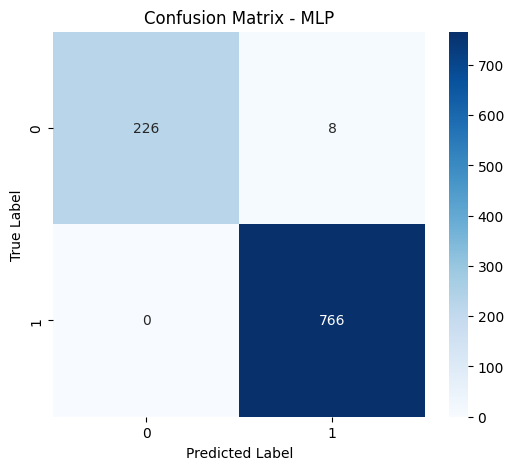

In [52]:
cm = confusion_matrix(y_test, y_pred)

plt.figure(figsize=(6,5))
sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    cbar=True
)

plt.title('Confusion Matrix - MLP')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')

plt.show()

The confusion matrix showed that 992 out of 1,000 observations were classified correctly. The model correctly identified 226 Low-Risk customers and 766 High-Risk customers. Only 8 Low-Risk customers were incorrectly classified as High-Risk, while no High-Risk customers were incorrectly classified as Low-Risk.

In [53]:
pipeline = Pipeline([
    ('scaler', StandardScaler()),
    ('mlp', MLPClassifier(
        hidden_layer_sizes=(100,),
        max_iter=1000,
        random_state=42
    ))
])

scores = cross_val_score(
    pipeline,
    x,
    y,
    cv=5,
    scoring='accuracy'
)

print(scores)
print("Mean Accuracy:", scores.mean())

[0.993 0.995 0.991 0.998 0.991]
Mean Accuracy: 0.9936


To validate the MLP model, five-fold cross-validation was performed. The model achieved accuracy scores ranging from 0.991 to 0.998, with a mean accuracy of 0.994. The consistency of these results indicates that the model is stable, reliable, and capable of producing accurate predictions across different subsets of the data.

In [ ]:
perm_importance = permutation_importance(
    mlp,
    x_test_scaled,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring='accuracy'
)

feature_importance = pd.DataFrame({
    "Feature": x.columns,
    "Importance": perm_importance.importances_mean
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print(feature_importance)
top_features = feature_importance["Feature"].head(10).tolist()

print("\nTop 10 Selected Features:")
print(top_features)

                       Feature  Importance
13                credit_score      0.2111
16          late_payment_count      0.2097
17        loan_default_history      0.0518
18                  fraud_flag      0.0173
7           avg_deposit_amount      0.0010
3                annual_income      0.0008
11   online_transfer_frequency      0.0007
8   debit_card_usage_frequency      0.0007
0                          age      0.0005
2            employment_status      0.0004
9          debit_card_spending      0.0003
6       num_deposits_per_month      0.0003
15      total_outstanding_debt      0.0002
19     loan_application_amount      0.0001
14              num_open_loans     -0.0003
1                       gender     -0.0004
5          avg_monthly_balance     -0.0005
4           account_age_months     -0.0009
12    atm_withdrawal_frequency     -0.0015
10       mobile_banking_logins     -0.0016

Top 10 Selected Features:
['credit_score', 'late_payment_count', 'loan_default_history', 'fraud_

The feature importance results from the MLP model showed that credit score (0.2111) and late payment count (0.2097) were the most important factors in predicting loan default. These two variables had a much greater influence on the model's predictions than the other variables, showing that a borrower's credit score and payment history play an important role in assessing credit risk. Previous loan defaults (0.0518) and fraud flag (0.0173) also contributed to the predictions, but their influence was smaller. Other variables, such as age, gender, account age, and mobile banking usage, had very low importance scores, suggesting that they contributed less to the model's predictions. Overall, the results indicate that a borrower's previous credit behavior is more important in predicting loan default than demographic information and everyday banking activities.

###Overall
The Random Forest and XGBoost models achieved the best overall performance, obtaining perfect scores across all evaluation metrics, including accuracy, ROC-AUC, and cross-validation accuracy. The MLP model also performed exceptionally well, achieving an accuracy of 99.2% and a mean cross-validation accuracy of 99.4%. In contrast, Logistic Regression achieved the lowest performance, with an accuracy of 91.2% and a mean cross-validation accuracy of 92.3%.
###Model Comparison
The better performance of the Random Forest, XGBoost, and MLP models suggests that the relationship between the predictor variables and credit risk is complex and involves patterns that are not always linear. Although Logistic Regression was able to correctly classify most of the observations, its performance was lower compared to the other models. This may be because Logistic Regression assumes a linear relationship between the predictor variables and the outcome being predicted, which can limit its ability to identify more complex relationships in the data. In contrast, Random Forest, XGBoost, and MLP can identify more complex patterns and interactions between different variables, allowing them to make more accurate predictions. These models can also capture how different factors, such as credit scores, late payment history, income, and previous loan defaults, may work together to influence a borrower's credit risk. Therefore, the results suggest that machine learning models were better able to identify the underlying patterns within the dataset and classify borrowers according to their credit risk.
###Chosen model
Although Random Forest and XGBoost achieved the same results across all evaluation measures, XGBoost was selected as the preferred model for this study. This decision was based on previous research, which has shown that XGBoost performs well in credit risk prediction and can identify complex relationships between different borrower characteristics. XGBoost also uses boosting and regularization  techniques, which help improve prediction accuracy and reduce the risk of overfitting. However, Random Forest also performed equally well and may be a good alternative because it is generally easier to implement and understand. The MLP model also achieved excellent results but required more data preparation and computing resources. Therefore, XGBoost was selected as the final model because of its strong support in previous research and its suitability for credit risk prediction. It is important to note that XGBoost was not selected because it performed better than Random Forest in this study, as both models achieved identical results. Instead, the decision was based on its proven effectiveness in previous studies and its ability to handle complex credit risk data.
###Feature selection
Feature selection was carried out using Logistic Regression coefficients, MLP permutation importance, and feature importance measures from Random Forest and Gradient Boost (XG Boost) models. The results consistently identified credit score, late payment count, previous loan defaults, fraud flag, and annual income as the five most important variables for predicting loan default. Credit score and late payment count had the highest importance scores across the models, showing that a borrower's credit history and repayment behavior are the strongest indicators of default risk. Previous loan defaults also played an important role, suggesting that borrowers who have defaulted before may be more likely to default again. Similarly, the fraud flag was identified as an important risk indicator, suggesting that accounts linked to fraudulent activities may have a higher risk of default.
The selected variables can be divided into two main groups. The first group consists of creditworthiness variables, which include credit score, late payment count, previous loan defaults, and fraud flag. These variables provide information about a borrower's credit history, repayment behavior, and overall risk level. They were also consistently ranked as the most important predictors across the different models. The second group consists of a financial variable, annual income, which provides an indication of a borrower's ability to repay a loan. Although annual income contributed to the predictions, its importance was lower than that of the creditworthiness variables.
###Conclusion
Overall, the findings suggest that a borrower's credit history and previous repayment behavior are more important in predicting loan default than demographic and everyday banking activities. The importance of credit score, late payment count, previous loan defaults, and fraud flag highlights the value of historical credit information when assessing borrower risk. These findings support the use of the five selected variables as important inputs when developing and evaluating loan default prediction models.
